In [3]:
import torch

if torch.cuda.is_available():
    print("GPU is available!")
    print(torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Select GPU runtime.")


GPU is available!
Tesla T4


In [4]:
!pip install -q diffusers transformers accelerate safetensors gradio

In [5]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to("cuda")

print("Stable Diffusion model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


  0%|          | 0/25 [00:00<?, ?it/s]

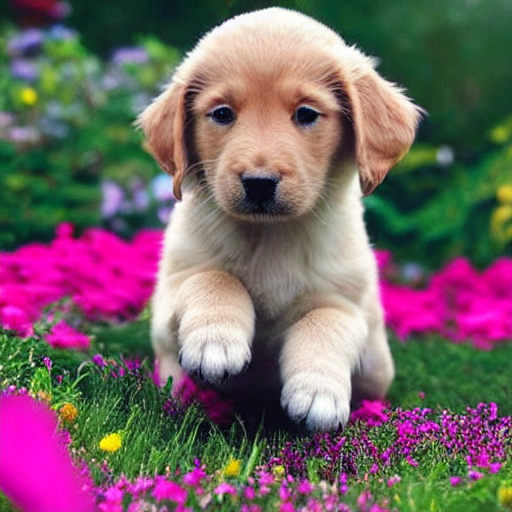

Image generated and saved!


In [6]:
from IPython.display import display

prompt = "A cute puppy playing in a garden, colorful flowers, realistic photography"

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)

image.save("generated_image.png")

print("Image generated and saved!")

In [7]:
import gradio as gr
import torch
import random

def generate_image(prompt, steps, guidance, seed):

    if not prompt.strip():
        raise gr.Error("Please enter an image prompt.")

    seed = int(seed)

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(seed)

    image = pipe(
        prompt=prompt,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        generator=generator
    ).images[0]

    return image

demo = gr.Interface(
    fn=generate_image,
    inputs=[
        gr.Textbox(
            label="Enter your prompt",
            placeholder="A beautiful sunset over mountains"
        ),
        gr.Slider(
            minimum=10,
            maximum=50,
            value=25,
            step=1,
            label="Inference Steps"
        ),
        gr.Slider(
            minimum=1,
            maximum=15,
            value=7.5,
            step=0.5,
            label="Guidance Scale"
        ),
        gr.Number(
            value=42,
            label="Seed"
        )
    ],
    outputs=gr.Image(label="Generated Image"),
    title="AI Image Generator",
    description="Generate images from text using Stable Diffusion"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://06f3ac5553a9719c39.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [8]:
import os
import csv
from datetime import datetime
from PIL import Image

# Create a folder to store generated images
os.makedirs("generated_images", exist_ok=True)

# CSV file for storing image details
csv_file = "generated_images/metadata.csv"

def generate_and_save(prompt, steps, guidance, seed):

    if not prompt.strip():
        raise gr.Error("Please enter a prompt!")

    seed = int(seed)

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(seed)

    # Generate image
    image = pipe(
        prompt=prompt,
        num_inference_steps=int(steps),
        guidance_scale=float(guidance),
        generator=generator
    ).images[0]

    # Create filename
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"image_{timestamp}.png"
    image_path = os.path.join("generated_images", filename)

    # Save image
    image.save(image_path)

    # Save metadata
    file_exists = os.path.exists(csv_file)

    with open(csv_file, "a", newline="") as file:
        writer = csv.writer(file)

        if not file_exists:
            writer.writerow([
                "Filename",
                "Prompt",
                "Inference Steps",
                "Guidance Scale",
                "Seed",
                "Date and Time"
            ])

        writer.writerow([
            filename,
            prompt,
            steps,
            guidance,
            seed,
            datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        ])

    print("Image and metadata saved successfully!")

    return image

# Create updated interface
demo = gr.Interface(
    fn=generate_and_save,

    inputs=[
        gr.Textbox(label="Enter Your Prompt"),
        gr.Slider(10, 50, value=25, step=1, label="Inference Steps"),
        gr.Slider(1, 15, value=7.5, step=0.5, label="Guidance Scale"),
        gr.Number(value=42, label="Seed")
    ],

    outputs=gr.Image(type="pil", label="Generated Image"),

    title="AI Image Generator Using Stable Diffusion",
    description="Generate and save AI images from text prompts."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3de4888e9f542e24ae.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
